# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/notebooks/meeting10_clinical_classifier_studio.ipynb)

# BME i9400 — Meeting 10
## Studio: An End-to-End Clinical Tabular Classifier

**Fall 2026 · Monday, October 19**

Today you build a diabetes classifier from the raw file to a reported result. The data are the full
dataset of Meeting 8, including the two measurements that were set aside. The classifier is a
pipeline that imputes missing values, standardises, and fits a logistic regression. A model and a
threshold are chosen on validation data, and the finished classifier is evaluated, with the
quantities of Meeting 9, on a test set that is used once.

**Agenda**

1. Loading the data and marking missing values
2. Splitting three ways
3. A pipeline: impute, standardise, fit
4. Choosing a model on validation data
5. Choosing a threshold on validation data
6. The test set, used once
7. Submitting your work

Section 1 is done for you — just read and run it. Sections 2 to 6 contain tasks marked `TODO` that
you are asked to complete. Each task ends with checks that must pass before you move on.

---
## 1 — Loading the data and marking missing values

The data are the 768 women of the Pima study of Meetings 8 and 9 (Smith, Everhart, Dickson, Knowler
and Johannes, 1988). In the file, a zero was recorded where a measurement is missing. Meeting 8
removed the 44 women with a missing glucose, blood pressure, or BMI, and set aside skin-fold
thickness and insulin, which are missing for 30% and 49% of the women. Today every woman and every
measurement is kept.

The first step replaces each impossible zero with `NaN`, so that a missing value can no longer be
mistaken for a measurement.

> `NaN` ("not a number") is the value that NumPy and pandas use to mark a missing entry. pandas
> skips it when computing a summary such as `df.median()`. A zero, by contrast, would be included
> in the median as if it had been measured.
>
> Zero pregnancies is a real value and is left alone. The pedigree function and age contain no
> zeros.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/diabetes.csv"
df  = pd.read_csv(URL)

measured = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[measured] = df[measured].replace(0, np.nan)          # a recorded zero means "not measured"

print(f"women: {len(df)}    with diabetes within five years: {df['Outcome'].sum()} "
      f"(prevalence {100 * df['Outcome'].mean():.1f}%)")
print(f"women with at least one missing measurement: {df.isna().any(axis=1).sum()}    "
      f"women with all eight: {len(df.dropna())}\n")

print(f"{'':<16}{'missing':>9}{'':>9}{'prevalence when':>20}{'prevalence when':>18}")
print(f"{'':<16}{'(women)':>9}{'(%)':>9}{'missing':>20}{'measured':>18}")
for col in measured:
    m = df[col].isna()
    print(f"{col:<16}{m.sum():>9d}{100 * m.mean():>9.1f}"
          f"{100 * df.loc[m, 'Outcome'].mean():>19.1f}%{100 * df.loc[~m, 'Outcome'].mean():>17.1f}%")

dropped = df[["Glucose", "BloodPressure", "BMI"]].isna().any(axis=1)
print(f"\nthe {dropped.sum()} women removed in Meeting 8: prevalence {100 * df.loc[dropped, 'Outcome'].mean():.1f}%")
df.head(4)

women: 768    with diabetes within five years: 268 (prevalence 34.9%)
women with at least one missing measurement: 376    women with all eight: 392

                  missing              prevalence when   prevalence when
                  (women)      (%)             missing          measured
Glucose                 5      0.7               40.0%             34.9%
BloodPressure          35      4.6               45.7%             34.4%
SkinThickness         227     29.6               38.8%             33.3%
Insulin               374     48.7               36.9%             33.0%
BMI                    11      1.4               18.2%             35.1%

the 44 women removed in Meeting 8: prevalence 43.2%


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0


Almost half of the women (376 of 768) are missing at least one measurement, so a model restricted
to complete records would use only 392 women. Whether a value is missing is also weakly related to
the outcome: diabetes is more common among the women whose insulin, skin-fold thickness, or blood
pressure was not recorded, and the 44 women removed in Meeting 8 had a prevalence of 43%, against
34% in the rest. Removing them made the cohort slightly healthier than the one the study enrolled.

> Missing values are **missing completely at random** when whether a value is missing is unrelated
> to anything else about the patient. Only then does deleting incomplete records leave the
> population unchanged. In clinical data, a test is often ordered, or skipped, because of the
> patient's condition, so this assumption rarely holds.

The differences for glucose and BMI rest on 5 and 11 women and should not be read too closely.
Section 4 tests whether the information in missingness improves the classifier.

---
## 2 — Splitting three ways

Meetings 7 to 9 split the data into two sets. Today two choices are made from data — which model
(section 4) and which threshold (section 5) — before the final evaluation, so the data are split
three ways:

- the **training set**, 60%: every weight, and every imputation and standardisation statistic, is
  computed here
- the **validation set**, 20%: used to choose between models and to choose the threshold
- the **test set**, 20%: used once, in section 6, after every choice has been made

> The test set estimates how the finished classifier will perform on women it has never seen. When
> a choice is made by looking at a set, that set's numbers become optimistic for the option that was
> chosen (Meeting 7, question 2). The validation set absorbs this optimism, so that the test set
> stays unbiased.
>
> Two calls to `train_test_split` give three sets. The first separates the test set. The second
> divides the remaining 80% into training and validation; 25% of 80% is 20% of the whole.
> `stratify=y` keeps the prevalence the same in every set (Meeting 9, section 7).

`X` is kept as a pandas DataFrame so that columns can be selected by name in section 4.

In [2]:
from sklearn.model_selection import train_test_split

features_all = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI",
                "DiabetesPedigreeFunction", "Age"]
X = df[features_all]
y = df["Outcome"].values

# --- TODO: split off a stratified 20% test set, then divide the rest into 75% training and 25% validation ---
#     stratify both splits, and use random_state=9400 in both calls
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=9400)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=9400)

assert X_test is not None and X_train is not None, "Fill in both splits."
assert (len(X_train), len(X_val), len(X_test)) == (460, 154, 154), \
    f"Expected 460 / 154 / 154 women, got {len(X_train)} / {len(X_val)} / {len(X_test)}."
assert set(X_train.index).isdisjoint(X_val.index) and set(X_train.index).isdisjoint(X_test.index) \
    and set(X_val.index).isdisjoint(X_test.index), "No woman may appear in two sets."
assert max(abs(s.mean() - y.mean()) for s in (y_train, y_val, y_test)) < 0.01, "Stratify both splits."

print(f"{'':<12}{'women':>7}{'with diabetes':>15}{'prevalence':>12}{'with a missing value':>23}")
for name, Xs, ys in [("training", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:<12}{len(ys):>7}{ys.sum():>15}{100 * ys.mean():>11.1f}%{Xs.isna().any(axis=1).sum():>23}")

              women  with diabetes  prevalence   with a missing value
training        460            160       34.8%                    228
validation      154             54       35.1%                     81
test            154             54       35.1%                     67


---
## 3 — A pipeline: impute, standardise, fit

Two preprocessing steps come before the model, and each computes statistics from data:

- **imputation** replaces each missing value with the median of that feature over the training set
- **standardisation** (Meeting 7, section 4) subtracts each feature's training mean and divides by
  its training standard deviation

> **Imputation** means filling in a missing value with an estimate. The median is used rather than
> the mean because insulin and skin-fold thickness are skewed: a few very large values pull the
> mean upward, while the median is unaffected by them.
>
> A **missing-value indicator** is an extra column that is $1$ where the value was missing and $0$
> where it was measured. With indicators, the model can learn a separate weight for "insulin was
> not measured", which section 1 suggested may carry information.

Both steps follow the rule of Meeting 7: statistics are computed on the training set only and then
applied, unchanged, to the validation and test sets. A median computed on all 768 women would let
the validation and test women influence the model, which is **leakage**.

A scikit-learn **`Pipeline`** enforces this rule. A pipeline is a list of named steps. Calling
`fit` on the training data fits each step in turn and passes its output to the next step; calling
`predict_proba` on new data applies every step using the statistics fitted on the training set.

> In scikit-learn, `fit` computes something from the data — a median, a mean, a set of weights —
> and `transform` applies what was computed. A pipeline calls `fit` and `transform` on the training
> set, and only `transform` on any other set. Meeting 11 shows why this matters most inside
> cross-validation.
>
> Indexing a pipeline with a slice gives the steps in that range: `pipe[:-1]` is every step except
> the model, so `pipe[:-1].transform(X_val)` returns the imputed, standardised validation features.

The three steps:

| name | class | arguments |
|---|---|---|
| `"impute"` | `SimpleImputer` | `strategy="median"`, `add_indicator=indicators` |
| `"scale"` | `StandardScaler` | none |
| `"model"` | `LogisticRegression` | `penalty=None`, `max_iter=1000` |

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def make_pipeline(indicators=False):
    # Median imputation (with or without missing-value indicators), standardisation, logistic regression.
    # --- TODO: return Pipeline([("impute", ...), ("scale", ...), ("model", ...)]) using the table above ---
    impute = ("impute", SimpleImputer(strategy="median", add_indicator=indicators))
    scale = ("scale", StandardScaler())
    model = ("model", LogisticRegression(penalty=None, max_iter=1000))
    return Pipeline([impute, scale, model])

pipe = make_pipeline()
assert pipe is not None, "Fill in make_pipeline()."
assert list(pipe.named_steps) == ["impute", "scale", "model"], "Name the steps 'impute', 'scale', 'model', in that order."
pipe.fit(X_train, y_train)

medians = pipe.named_steps["impute"].statistics_
assert np.allclose(medians, X_train.median()), "The imputed values should be the medians of the training set."
Z_val = pipe[:-1].transform(X_val)
assert not np.isnan(Z_val).any(), "No missing values should survive imputation."
assert np.allclose(pipe[:-1].transform(X_train).mean(axis=0), 0), "The training features should have mean 0 after scaling."
assert make_pipeline(indicators=True).fit(X_train, y_train)[:-1].transform(X_val).shape[1] > len(features_all), \
    "With indicators=True, the imputer should add indicator columns."

weights = pipe.named_steps["model"].coef_[0]
print(f"{'':<26}{'missing in training':>21}{'training median':>17}{'all 768 women':>15}{'weight':>9}")
for name, med, w in zip(features_all, medians, weights):
    print(f"{name:<26}{X_train[name].isna().sum():>21}{med:>17.4g}{df[name].median():>15.4g}{w:>+9.2f}")

                            missing in training  training median  all 768 women   weight
Pregnancies                                   0                3              3    +0.42
Glucose                                       5              117            117    +1.16
BloodPressure                                22               72             72    -0.12
SkinThickness                               135               29             29    +0.14
Insulin                                     226              130            125    -0.16
BMI                                           6             32.4           32.3    +0.61
DiabetesPedigreeFunction                      0           0.3865         0.3725    +0.29
Age                                           0               29             29    +0.22


The training medians are close to the medians of all 768 women, so in this dataset the leakage that
the pipeline prevents would have been small. The habit matters more than the size of the effect
here: in Meeting 11 the same mistake, made inside cross-validation, produces optimistic results.

The weights are on standardised features and can be compared (Meeting 7). Glucose and BMI carry the
largest weights, as in Meeting 8. Insulin and skin-fold thickness, now included, receive weights
smaller than any feature except blood pressure.

---
## 4 — Choosing a model on validation data

Three candidate models:

- **A** — the six measurements of Meeting 8, with the few missing glucose, blood pressure, and BMI
  values imputed
- **B** — all eight measurements, imputed
- **C** — all eight measurements, imputed, with missing-value indicators

Each is fitted on the training set and scored on the validation set by its AUC (Meeting 9,
section 5). The AUC is used because it does not depend on a threshold, and the threshold has not yet
been chosen.

> The candidate with the highest validation AUC is selected. Its validation AUC is then slightly
> optimistic, for the reason given in section 2. The test set in section 6 provides the unbiased
> estimate.
>
> `X_train[cols]` selects the columns named in the list `cols`. A pipeline fitted on those columns
> must be given the same columns when it predicts.

In [4]:
from sklearn.metrics import roc_auc_score

features_six = ["Pregnancies", "Glucose", "BloodPressure", "BMI", "DiabetesPedigreeFunction", "Age"]
candidates = {
    "A: six measurements":                (features_six, False),
    "B: eight measurements":              (features_all, False),
    "C: eight measurements + indicators": (features_all, True),
}

fitted, val_auc = {}, {}
for name, (cols, indicators) in candidates.items():
    # --- TODO: fit make_pipeline(indicators) on the training set, using only the columns `cols`;
    #           then compute the AUC of its predicted probabilities on the validation set ---
    fitted[name] = make_pipeline(indicators).fit(X_train[cols], y_train)
    val_auc[name] = roc_auc_score(y_val, fitted[name].predict_proba(X_val[cols])[:, 1])

assert all(v is not None for v in val_auc.values()), "Fill in the loop."
cols_c = candidates["C: eight measurements + indicators"][0]
check  = roc_auc_score(y_val, make_pipeline(True).fit(X_train[cols_c], y_train).predict_proba(X_val[cols_c])[:, 1])
assert np.isclose(val_auc["C: eight measurements + indicators"], check), \
    "Fit on the training set, then score predict_proba(...)[:, 1] on the validation set."

best_name = max(val_auc, key=val_auc.get)
for name in candidates:
    print(f"{name:<38} validation AUC {val_auc[name]:.3f}{'   <- selected' if name == best_name else ''}")

print("\ncorrelation between features, over the women in whom both were measured:")
print(f"  glucose and insulin:         {df['Glucose'].corr(df['Insulin']):.2f}")
print(f"  BMI and skin-fold thickness: {df['BMI'].corr(df['SkinThickness']):.2f}")

A: six measurements                    validation AUC 0.832   <- selected
B: eight measurements                  validation AUC 0.823
C: eight measurements + indicators     validation AUC 0.814

correlation between features, over the women in whom both were measured:
  glucose and insulin:         0.58
  BMI and skin-fold thickness: 0.65


The two measurements set aside in Meeting 8 do not improve the classifier. Model A, with six
measurements, has a validation AUC of about $0.83$; adding insulin and skin-fold thickness lowers it
by about $0.01$, and adding the missing-value indicators lowers it by about another $0.01$. Two
reasons are visible in this notebook:

- **Little new information.** Insulin is correlated with glucose ($r = 0.58$) and skin-fold
  thickness with BMI ($r = 0.65$). Most of what they say about diabetes is already said by the
  features that model A contains.
- **Much of the new information is imputed.** Half of the insulin values and 30% of the skin-fold
  values are the training median, the same number for every woman in whom the measurement is missing.

The differences are also small compared with the uncertainty of the AUC itself. With 54 positive and
100 negative women in the validation set, the standard error of an AUC near $0.83$ is about $0.04$.
When the split is repeated with 200 different random seeds, model A has the highest validation AUC
in 113, model C in 62, and model B in 25. When candidates cannot be distinguished on validation
data, the simpler one is preferred: it has fewer weights to estimate and needs fewer measurements
from each patient. Model A is selected.

---
## 5 — Choosing a threshold on validation data

The classifier is to be used for screening: women it calls positive are referred for follow-up
testing. A missed case is judged more costly than an unnecessary referral, so the threshold is set by
the first method of Meeting 9, section 4 — **a required sensitivity**, here $0.85$. Among the
thresholds that reach a sensitivity of $0.85$ on the validation set, the largest is chosen, because
a larger threshold calls fewer women positive and so gives the highest specificity.

> `roc_curve` returns three arrays: the false positive rates, the true positive rates (the
> sensitivities), and the thresholds that produce them. The thresholds are in **decreasing** order,
> so the sensitivity increases along the arrays. `drop_intermediate=False` keeps every threshold.
>
> `np.argmax` applied to a boolean array returns the index of its first `True`. So
> `np.argmax(tpr_v >= 0.85)` is the index of the first threshold, and therefore the largest, whose
> sensitivity is at least $0.85$.

In [5]:
from sklearn.metrics import roc_curve

cols   = candidates[best_name][0]
final  = fitted[best_name]
p_val  = final.predict_proba(X_val[cols])[:, 1]
fpr_v, tpr_v, thr_v = roc_curve(y_val, p_val, drop_intermediate=False)

# --- TODO: the index of the largest threshold with validation sensitivity >= 0.85, and that threshold ---
i_star = np.argmax(tpr_v >= 0.85)
t_star = thr_v[i_star]

assert i_star is not None and t_star is not None, "Fill in i_star and t_star."
assert tpr_v[i_star] >= 0.85, "The chosen threshold must reach a validation sensitivity of 0.85."
assert i_star == 0 or tpr_v[i_star - 1] < 0.85, "Choose the largest threshold that reaches 0.85."
assert t_star == thr_v[i_star], "t_star should be the threshold at index i_star."

print(f"selected model: {best_name}")
print(f"threshold t* = {t_star:.3f}")
print(f"on the validation set:  sensitivity {tpr_v[i_star]:.3f}   specificity {1 - fpr_v[i_star]:.3f}")

selected model: A: six measurements
threshold t* = 0.248
on the validation set:  sensitivity 0.852   specificity 0.620


The chosen threshold is about $0.25$, far below $1/2$, as Meeting 9 found for a high required
sensitivity. On the validation set it finds 46 of the 54 women who developed diabetes (sensitivity
$0.85$) and correctly clears 62% of those who did not. These two numbers were obtained by choosing
the threshold on this set, so they are not the result to report.

Every part of the classifier is now fixed: the features, the imputation and standardisation
statistics, the weights, and the threshold.

---
## 6 — The test set, used once

The fixed classifier is applied to the 154 test women and every quantity of Meeting 9 is reported.
`summarise` is the function of Meeting 9, section 3.

> **Used once** means that nothing is changed after the test numbers have been seen. If the model or
> the threshold is revised in response to the test results, the test set has become a second
> validation set, its numbers are optimistic, and a new test set would be needed to report an
> unbiased result.

In [6]:
from sklearn.metrics import average_precision_score, precision_recall_curve

def summarise(y_true, p, t):
    # Every quantity of Meeting 9, section 3, for the decisions p >= t.
    pred = (p >= t).astype(int)
    TP = np.sum((pred == 1) & (y_true == 1)); FN = np.sum((pred == 0) & (y_true == 1))
    FP = np.sum((pred == 1) & (y_true == 0)); TN = np.sum((pred == 0) & (y_true == 0))
    return {"TP": TP, "FN": FN, "FP": FP, "TN": TN,
            "sensitivity": TP / (TP + FN), "specificity": TN / (TN + FP), "FPR": FP / (FP + TN),
            "precision": TP / (TP + FP), "NPV": TN / (TN + FN), "accuracy": (TP + TN) / len(y_true)}

# --- TODO: the selected model's probabilities on the test set, and the summary at the threshold t_star ---
p_test = final.predict_proba(X_test[cols])[:, 1]
report = summarise(y_test, p_test, t_star)

assert p_test is not None and report is not None, "Fill in p_test and report."
assert p_test.shape == (len(y_test),), "p_test should hold one probability for each test woman."
assert report["TP"] + report["FN"] == y_test.sum(), "The summary should be computed on the test labels."

val = summarise(y_val, p_val, t_star)
print(f"selected model: {best_name}    threshold t* = {t_star:.3f}\n")
print(f"{'':<16}{'validation':>12}{'test':>10}")
print(f"{'women':<16}{len(y_val):>12}{len(y_test):>10}")
print(f"{'prevalence':<16}{y_val.mean():>12.3f}{y_test.mean():>10.3f}")
print(f"{'AUC':<16}{roc_auc_score(y_val, p_val):>12.3f}{roc_auc_score(y_test, p_test):>10.3f}")
print(f"{'AP':<16}{average_precision_score(y_val, p_val):>12.3f}{average_precision_score(y_test, p_test):>10.3f}")
for k in ["sensitivity", "specificity", "precision", "NPV", "accuracy"]:
    print(f"{k:<16}{val[k]:>12.3f}{report[k]:>10.3f}")
print(f"\ntest confusion matrix at t*:")
print(f"{'':<12}{'predicted 1':>14}{'predicted 0':>14}")
print(f"{'actual 1':<12}{report['TP']:>14}{report['FN']:>14}")
print(f"{'actual 0':<12}{report['FP']:>14}{report['TN']:>14}")

selected model: A: six measurements    threshold t* = 0.248

                  validation      test
women                    154       154
prevalence             0.351     0.351
AUC                    0.832     0.833
AP                     0.711     0.778
sensitivity            0.852     0.759
specificity            0.620     0.730
precision              0.548     0.603
NPV                    0.886     0.849
accuracy               0.701     0.740

test confusion matrix at t*:
               predicted 1   predicted 0
actual 1                41            13
actual 0                27            73


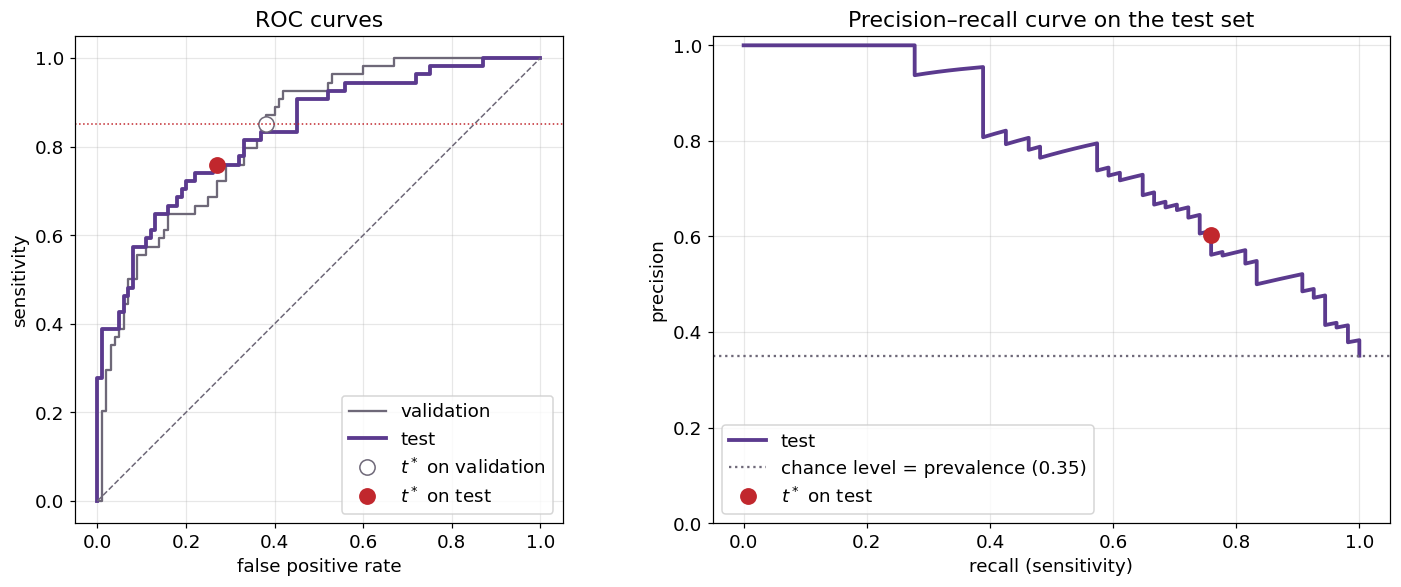

In [7]:
# Done for you: the ROC and precision-recall curves on the test set, with the chosen operating point.
fpr_t, tpr_t, _ = roc_curve(y_test, p_test)
prec_t, rec_t, _ = precision_recall_curve(y_test, p_test)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
axes[0].plot(fpr_v, tpr_v, lw=1.5, color="#6e6878", label="validation")
axes[0].plot(fpr_t, tpr_t, lw=2.5, color="#5b3a8e", label="test")
axes[0].plot([0, 1], [0, 1], "--", color="#6e6878", lw=1)
axes[0].plot(val["FPR"], val["sensitivity"], "o", ms=10, mfc="white", color="#6e6878", label=f"$t^*$ on validation")
axes[0].plot(report["FPR"], report["sensitivity"], "o", ms=10, color="#c1272d", label=f"$t^*$ on test")
axes[0].axhline(0.85, ls=":", color="#c1272d", lw=1)
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("sensitivity")
axes[0].set_title("ROC curves"); axes[0].set_aspect("equal"); axes[0].legend(loc="lower right")

axes[1].plot(rec_t, prec_t, lw=2.5, color="#5b3a8e", label="test")
axes[1].axhline(y_test.mean(), ls=":", color="#6e6878", label=f"chance level = prevalence ({y_test.mean():.2f})")
axes[1].plot(report["sensitivity"], report["precision"], "o", ms=10, color="#c1272d", label="$t^*$ on test")
axes[1].set_xlabel("recall (sensitivity)"); axes[1].set_ylabel("precision"); axes[1].set_ylim(0, 1.02)
axes[1].set_title("Precision–recall curve on the test set"); axes[1].legend(loc="lower left")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

On the test set the classifier has an AUC of $0.83$, the same as on the validation set. At the
threshold $t^*$ it finds 41 of the 54 women who developed diabetes, a sensitivity of $0.76$, and
correctly clears 73% of those who did not. Of the women it refers, 60% develop diabetes; this
precision holds at the test set's prevalence of 35% and would be lower in a population where diabetes
is rarer (Meeting 9, section 6).

The sensitivity falls short of the $0.85$ that the threshold was chosen to achieve. Two effects
contribute:

- **Selection.** $t^*$ was the largest threshold that reached $0.85$ on the validation women, so on
  that set it meets the target by construction. On a new sample the same threshold has no reason to
  do better, and the selection makes it more likely to do worse.
- **Sampling.** A sensitivity estimated from 54 women has a standard error of about
  $\sqrt{0.85 \times 0.15 / 54} \approx 0.05$. A shortfall of $0.09$ is within the range of
  variation between two samples of this size.

The reported result is the test result: a sensitivity of $0.76$ and a specificity of $0.73$ at
$t^* \approx 0.25$. The validation numbers describe how the choices were made and are not reported
as the classifier's performance. If the screening programme requires $0.85$ in practice, the
threshold is chosen with a margin, or on more data; Meeting 12 replaces the single validation set
with nested cross-validation, and Meeting 20 attaches confidence intervals to the test estimates.

> The test AUC is lower than the $0.90$ of Meeting 9. The two numbers come from different test sets
> and from training sets of different sizes (460 women here, 579 there). Single-split estimates from a
> dataset of this size can differ by several hundredths, which is the subject of Meeting 20.

---
## 7 — Submitting your work

**Due at 11:59 PM EST on Monday, October 19.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_meeting10.ipynb` and move it into the `checkins/` folder
   of your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

### Two short questions

Answer in the cell below before you submit.

In [8]:
# One or two sentences each.

# 1. Section 1 found that diabetes was more common among women whose insulin was not measured, and
#    model C gives a weight to an indicator of that. Suppose the clinic that will use the classifier
#    measures insulin for every patient. What happens to the indicator, and why does this make
#    missing-value indicators risky when a model is moved to a new setting?
Q1 = "The insulin-missing indicator will always be 0 because every patient has insulin measured. Missing-value indicators can be the result of a clinic's testing practices, so their relationship with diabetes be accurate for other clinics with different practices."

# 2. The test sensitivity (section 6) was lower than the 0.85 required. A colleague proposes lowering
#    the threshold until the test sensitivity reaches 0.85, and reporting that. What is wrong with
#    this, and what should be done instead?
Q2 = "Lowering the threshold based on test results would turn the test set into tuning data, which could lead to the reported performance being optimistically biased. Instead, it is important to report the original test result and make sure that any revised threshold should be chosen using training or validation data, and then it can be evaluated on a new test set."

for name, ans in [("Q1", Q1), ("Q2", Q2)]:
    assert len(ans.strip()) >= 30, f"{name} looks empty or very short."
print("Answers recorded.")

Answers recorded.
